# 04 - Deep hedging sous shifted Bergomi (rough)

Meme pipeline qu'au notebook 03 (VNN / SNN / RNN, options europeenne, asiatique,
lookback) mais sous le modele **shifted Bergomi** a volatilite rugueuse (rough),
qui est **non-markovien** : la volatilite depend de toute l'histoire du brownien.

C'est le cas ou le **SNN** (signatures) est attendu meilleur que le VNN/RNN.

Les P&L de test sont sauvegardes en fin de notebook (`results/bergomi_pnl.npz`)
pour reutilisation par le notebook 06 (comparaison).

In [10]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

from deep_hedging import RNN, SNN, VNN, evaluate, evaluate_rnn, get_optimizer, training_loop, training_rnn
from signatures import compute_signatures
from utils.plotting import plot_pnl_distribution

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

# Parametres shifted Bergomi
S0, f0, K = 1.0, 0.0625, 1.0
varsigma, epsilon, H, rho = 1.6, 1/52, 0.1, -0.7
T, J = 1/12, 126
I_train, I_test = 10_000, 20_000

# Entrainement
NUM_EPOCHS = 64
BATCH = 64

device: cuda


In [12]:
from models import compute_payoff_asian, compute_payoff_europeen, compute_payoff_lookback, simulate_shifted_bergomi

S_train, dS_train, sigma_train, states_train, W_hat_train = simulate_shifted_bergomi(
    S0, varsigma, f0, epsilon, H, rho, T, J, I_train, seed=42)
S_test, dS_test, sigma_test, states_test, W_hat_test = simulate_shifted_bergomi(
    S0, varsigma, f0, epsilon, H, rho, T, J, I_test, seed=123)

payoff_eu_train = compute_payoff_europeen(S_train, K)
payoff_eu_test  = compute_payoff_europeen(S_test, K)
payoff_as_train = compute_payoff_asian(S_train, K)
payoff_as_test  = compute_payoff_asian(S_test, K)
payoff_lb_train = compute_payoff_lookback(S_train)
payoff_lb_test  = compute_payoff_lookback(S_test)

print('states:', states_train.shape, '| dS:', dS_train.shape)

states: (10000, 127, 3) | dS: (10000, 126)


In [13]:
sig_train = compute_signatures(states_train, depth=4)
sig_test  = compute_signatures(states_test, depth=4)
SIG_DIM = sig_train.shape[-1]
print('signature shape:', sig_train.shape, '| SIG_DIM =', SIG_DIM)

signature shape: (10000, 126, 120) | SIG_DIM = 120


In [14]:
states_train_t = torch.tensor(states_train, dtype=torch.float32)
states_test_t  = torch.tensor(states_test,  dtype=torch.float32)
dS_train_t = torch.tensor(dS_train, dtype=torch.float32)
dS_test_t  = torch.tensor(dS_test,  dtype=torch.float32)
sig_train_t = torch.tensor(sig_train, dtype=torch.float32)
sig_test_t  = torch.tensor(sig_test,  dtype=torch.float32)

In [15]:
def run_mlp(net_class, in_features, x_train_t, x_test_t, payoff_train, payoff_test, label):
    """Entraine un reseau par pas de temps (VNN ou SNN) et renvoie le P&L de couverture (numpy)."""
    model = net_class(input_features=in_features, output_features=1).to(device)
    opt, sched = get_optimizer(model)
    train_loader = DataLoader(
        TensorDataset(x_train_t, dS_train_t, torch.tensor(payoff_train, dtype=torch.float32)),
        batch_size=BATCH, shuffle=True)
    test_loader = DataLoader(
        TensorDataset(x_test_t, dS_test_t, torch.tensor(payoff_test, dtype=torch.float32)),
        batch_size=BATCH, shuffle=False)
    training_loop(model, train_loader, BATCH, opt, sched, NUM_EPOCHS, device)
    pnl, mse, mpnl = evaluate(model, test_loader, device)
    print(f'{label:14} MSE={float(mse):.3e}  meanPnL={float(mpnl):.3e}')
    return pnl.cpu().numpy()


def run_rnn(payoff_train, payoff_test, label):
    """Entraine le RNN (LSTM) sur les etats (t, S, sigma) et renvoie le P&L de couverture (numpy)."""
    model = RNN(input_features=3, output_features=1).to(device)
    opt, sched = get_optimizer(model)
    train_loader = DataLoader(
        TensorDataset(states_train_t, dS_train_t, torch.tensor(payoff_train, dtype=torch.float32)),
        batch_size=BATCH, shuffle=True)
    test_loader = DataLoader(
        TensorDataset(states_test_t, dS_test_t, torch.tensor(payoff_test, dtype=torch.float32)),
        batch_size=BATCH, shuffle=False)
    training_rnn(model, train_loader, BATCH, opt, sched, NUM_EPOCHS, device)
    pnl, mse, mpnl = evaluate_rnn(model, test_loader, device)
    print(f'{label:14} MSE={float(mse):.3e}  meanPnL={float(mpnl):.3e}')
    return pnl.cpu().numpy()

## Cas 1 : option europeenne

  2%|▏         | 1/64 [00:01<01:57,  1.86s/it]

Epoch =0 , Loss =0.00018809980247169733


  8%|▊         | 5/64 [00:03<00:36,  1.63it/s]

Epoch =4 , Loss =5.426103598438203e-05


 14%|█▍        | 9/64 [00:05<00:28,  1.90it/s]

Epoch =8 , Loss =0.00010355112317483872


... (92 outputs left out)

 95%|█████████▌| 61/64 [00:32<00:01,  1.77it/s]

Epoch =60 , Loss =7.38173839636147e-05


100%|██████████| 64/64 [00:34<00:00,  1.87it/s]


EU RNN         MSE=8.244e-05  meanPnL=-5.496e-05


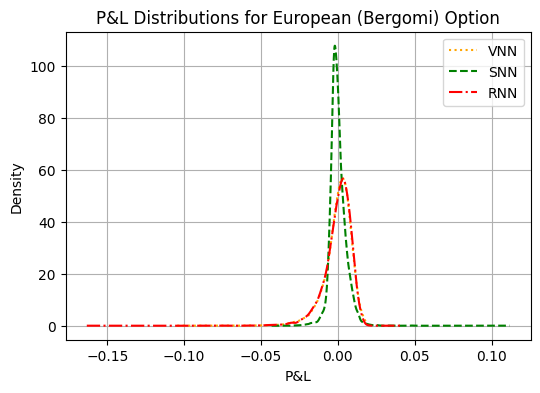

In [16]:
# --- European (Bergomi) ---
pnl_eu_vnn = run_mlp(VNN, 3,       states_train_t, states_test_t, payoff_eu_train, payoff_eu_test, 'EU VNN')
pnl_eu_snn = run_mlp(SNN, SIG_DIM, sig_train_t,    sig_test_t,    payoff_eu_train, payoff_eu_test, 'EU SNN')
pnl_eu_rnn = run_rnn(payoff_eu_train, payoff_eu_test, 'EU RNN')

plot_pnl_distribution([
    (pnl_eu_vnn, 'VNN', 'orange', 'dotted'),
    (pnl_eu_snn, 'SNN', 'green',  'dashed'),
    (pnl_eu_rnn, 'RNN', 'red',    'dashdot'),
], title='European (Bergomi)')

## Cas 2 : option asiatique

  2%|▏         | 1/64 [00:00<00:27,  2.30it/s]

Epoch =0 , Loss =0.00020373976440168917


  8%|▊         | 5/64 [00:01<00:22,  2.68it/s]

Epoch =4 , Loss =2.8317695978330448e-05


 14%|█▍        | 9/64 [00:03<00:21,  2.57it/s]

Epoch =8 , Loss =4.5164444600231946e-05


... (92 outputs left out)

 95%|█████████▌| 61/64 [00:32<00:01,  2.05it/s]

Epoch =60 , Loss =1.957993663381785e-05


100%|██████████| 64/64 [00:34<00:00,  1.86it/s]


AS RNN         MSE=2.011e-05  meanPnL=5.130e-05


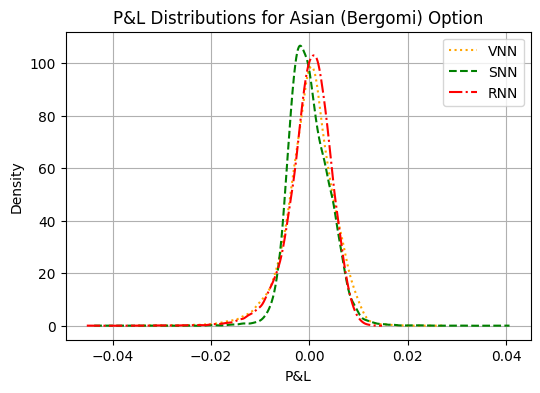

In [17]:
# --- Asian (Bergomi) ---
pnl_as_vnn = run_mlp(VNN, 3,       states_train_t, states_test_t, payoff_as_train, payoff_as_test, 'AS VNN')
pnl_as_snn = run_mlp(SNN, SIG_DIM, sig_train_t,    sig_test_t,    payoff_as_train, payoff_as_test, 'AS SNN')
pnl_as_rnn = run_rnn(payoff_as_train, payoff_as_test, 'AS RNN')

plot_pnl_distribution([
    (pnl_as_vnn, 'VNN', 'orange', 'dotted'),
    (pnl_as_snn, 'SNN', 'green',  'dashed'),
    (pnl_as_rnn, 'RNN', 'red',    'dashdot'),
], title='Asian (Bergomi)')

## Cas 3 : option lookback

  2%|▏         | 1/64 [00:00<00:26,  2.36it/s]

Epoch =0 , Loss =0.0006122388876974583


  8%|▊         | 5/64 [00:02<00:27,  2.18it/s]

Epoch =4 , Loss =0.0005646782810799778


 14%|█▍        | 9/64 [00:04<00:28,  1.91it/s]

Epoch =8 , Loss =0.000372649694327265


... (92 outputs left out)

 95%|█████████▌| 61/64 [00:33<00:01,  1.84it/s]

Epoch =60 , Loss =0.00043252011528238654


100%|██████████| 64/64 [00:35<00:00,  1.80it/s]


LB RNN         MSE=4.421e-04  meanPnL=-2.928e-04


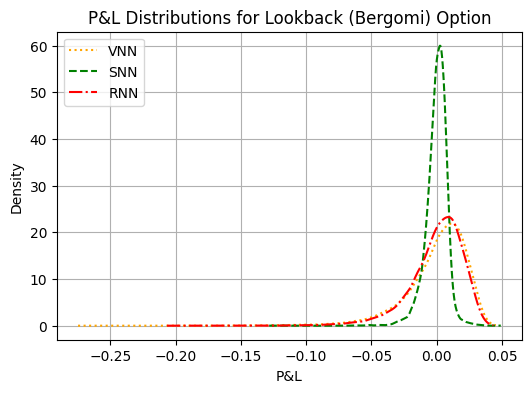

In [18]:
# --- Lookback (Bergomi) ---
pnl_lb_vnn = run_mlp(VNN, 3,       states_train_t, states_test_t, payoff_lb_train, payoff_lb_test, 'LB VNN')
pnl_lb_snn = run_mlp(SNN, SIG_DIM, sig_train_t,    sig_test_t,    payoff_lb_train, payoff_lb_test, 'LB SNN')
pnl_lb_rnn = run_rnn(payoff_lb_train, payoff_lb_test, 'LB RNN')

plot_pnl_distribution([
    (pnl_lb_vnn, 'VNN', 'orange', 'dotted'),
    (pnl_lb_snn, 'SNN', 'green',  'dashed'),
    (pnl_lb_rnn, 'RNN', 'red',    'dashdot'),
], title='Lookback (Bergomi)')

## Sauvegarde des P&L

In [19]:
# Sauvegarde des P&L de test pour reutilisation (notebooks 05 / 07) sans reentrainer
RESULTS = PROJECT_ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
np.savez(
    RESULTS / 'bergomi_pnl.npz',
    eu_vnn=pnl_eu_vnn, eu_snn=pnl_eu_snn, eu_rnn=pnl_eu_rnn,
    as_vnn=pnl_as_vnn, as_snn=pnl_as_snn, as_rnn=pnl_as_rnn,
    lb_vnn=pnl_lb_vnn, lb_snn=pnl_lb_snn, lb_rnn=pnl_lb_rnn,
)
print('P&L sauvegardes dans', RESULTS / 'bergomi_pnl.npz')

P&L sauvegardes dans c:\Users\LENOVOµ\Desktop\hedging_signatures\results\bergomi_pnl.npz
